In [40]:
import yfinance as yf
import pandas as pd
import numpy as np

dat = yf.Ticker("NVDA")


In [41]:
df = dat.history(period="10y", interval="1d")
lr = np.log(df["Close"] / df["Close"].shift(1)).dropna()
logreturns =  lr.to_numpy().reshape(-1, 1)
logreturns = logreturns[np.isfinite(logreturns.ravel())]
print(logreturns)

[[ 0.01627221]
 [ 0.00402708]
 [-0.02072373]
 ...
 [ 0.02509027]
 [-0.04496586]
 [-0.00590781]]


C:\Users\Devin Thanadabouth\PycharmProjects\HMM-Baseline\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\Users\Devin Thanadabouth\PycharmProjects\HMM-Baseline\.venv\Lib\site-packages\yfinance\utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
C:\Users\Devin Thanadabouth\PycharmProjects\HMM-Baseline\.venv\Lib\site-packages\yfinance\utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/what

In [42]:
from hmmlearn.hmm import GaussianHMM

model = GaussianHMM(n_components=3, covariance_type="diag", n_iter=1000, tol= 1e-3, random_state=67)

model.fit(logreturns)

states = model.predict(logreturns)



In [43]:
print(states)
print("Means:", model.means_.flatten())
print("Variances:", model.covars_.reshape(-1))
print("Transition matrix:\n", model.transmat_)
print("State counts:", np.bincount(states))

[1 1 1 ... 1 1 1]
Means: [ 0.01175104  0.00289435 -0.00059268]
Variances: [0.01322273 0.0004495  0.00151487]
Transition matrix:
 [[0.33683766 0.00438681 0.65877553]
 [0.00568142 0.98079367 0.0135249 ]
 [0.02036877 0.03921975 0.94041147]]
State counts: [  19 1798  696]


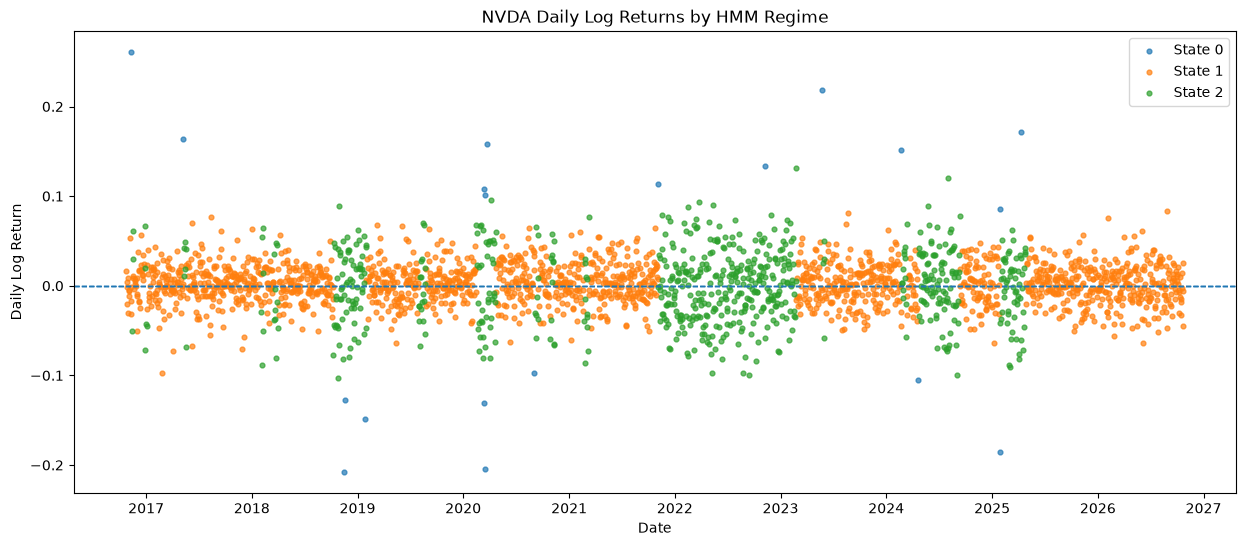

In [50]:
import matplotlib.pyplot as plt

returns = np.asarray(logreturns).reshape(-1)
results = pd.DataFrame({
    "Log_Return": returns,
    "State": states
})
results.index = df.index[-len(results):]
plt.figure(figsize=(15, 6))

for state in sorted(results["State"].unique()):
    subset = results[results["State"] == state]
    plt.scatter(
        subset.index,
        subset["Log_Return"],
        s=12,
        label=f"State {state}",
        alpha=0.7
    )
    plt.axhline(0, linestyle="--", linewidth=1)
plt.title("NVDA Daily Log Returns by HMM Regime")
plt.xlabel("Date")
plt.ylabel("Daily Log Return")
plt.legend()

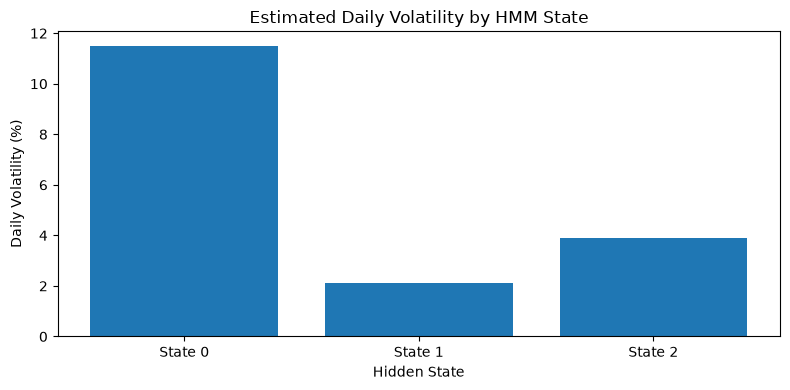

In [51]:
variances = model.covars_.reshape(-1)
daily_volatility = np.sqrt(variances)

plt.figure(figsize=(8, 4))
plt.bar(
    [f"State {i}" for i in range(model.n_components)],
    daily_volatility * 100
)

plt.title("Estimated Daily Volatility by HMM State")
plt.xlabel("Hidden State")
plt.ylabel("Daily Volatility (%)")
plt.tight_layout()
plt.show()